<div style="background:linear-gradient(135deg,#123524 0%,#1f5a45 45%,#2B5A82 100%);color:#fff;padding:40px 36px;border-radius:16px;font-family:system-ui,-apple-system,'Segoe UI',sans-serif">
  <div style="font-size:12px;letter-spacing:.16em;opacity:.75;text-transform:uppercase">43008 Reinforcement Learning &middot; Assignment 3 &middot; Team LMF</div>
  <div style="font-size:46px;font-weight:800;line-height:1.05;margin:12px 0 6px">Experiment: PPO</div>
  <div style="font-size:19px;opacity:.92">Proximal Policy Optimisation on AgriFlight-RL, crop-row flight stabilisation</div>
  <div style="height:1px;background:rgba(255,255,255,.28);margin:24px 0 18px"></div>
  <div style="display:flex;flex-wrap:wrap;gap:36px">
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student</div><div style="font-size:20px;font-weight:600">Nelkit Isael Chavez Calona</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student ID</div><div style="font-size:20px;font-weight:600">25609227</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Environment</div><div style="font-size:20px;font-weight:600">AgroDrone-v0 &middot; MuJoCo Skydio X2</div></div>
  </div>
</div>

### Contents

1. [Introduction](#intro): question, hypothesis, success criterion
2. [Setup](#setup): run mode, config, seeds, shared helpers, run folder, environment check
3. [Theory](#theory): the algorithm in your own words
4. [Implementation](#implementation): the code
5. [Training](#training): train once (or load), curve, stability
6. [Evaluation](#evaluation): held-out seeds, baselines, difficulty levels
7. [Results](#results): table and plots
8. [Discussion](#discussion): what worked, what did not, limits
9. [Contribution and reproducibility](#contribution): who did what, versions, references

<div style="border-left:4px solid rgb(140,90,43);background:rgba(140,90,43,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Template status (delete this box before submitting).</b> <code>Run all</code> works today and produces the baseline numbers. Cells marked <i>Write here</i> or <code>TODO</code> are yours. Do not edit the cells labelled <i>Shared, identical in all three notebooks</i>: the comparison is only fair if they stay the same.</div>

<a id="intro"></a>

## 1. Introduction

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> In about 150 words:<ul><li>The research question this notebook answers (not "train a drone")</li><li>What PPO is, in two sentences</li><li>Your hypothesis. Part B expects PPO to be the most stable of the three. Say whether you agree, and what result would change your mind.</li><li><b>Your success criterion, written before you see results</b>: the highest difficulty level you expect to clear (L0 to L4) and roughly how many samples it needs</li></ul></div>

<a id="setup"></a>

## 2. Setup

**2.1 Bootstrap.** Finds the repo (or clones it), fetches the Skydio X2 model from the public MuJoCo Menagerie and installs any missing dependencies. Works on **AWS SageMaker**, **Google Colab** and a local Jupyter. Nothing to edit.

<details>
<summary><b>First time on SageMaker? Click here: GitHub token + clone the repo (one-off, about 5 minutes)</b></summary>

The repo is **private**, so SageMaker needs a GitHub *personal access token* to clone it. Each team member creates their own.

**A. Create a fine-grained token on GitHub**
1. GitHub (top-right avatar) → **Settings** → **Developer settings** → **Personal access tokens** → **Fine-grained tokens** → **Generate new token**.
2. *Token name*: `sagemaker-agroflight`. *Expiration*: 30 days (covers the project).
3. *Resource owner*: `Nelkit`. *Repository access*: **Only select repositories** → `agroflight-rl`. (If `Nelkit` is not in the list, ask Nelkit to confirm you are a collaborator; a classic token with the `repo` scope also works.)
4. *Permissions* → *Repository permissions* → **Contents: Read and write** (write lets you push your results).
5. **Generate token** and copy it (`github_pat_...`). GitHub shows it only once. Never paste it into a notebook cell or commit it.

**B. Clone the repo in SageMaker (from a Terminal, not from a notebook cell)**

In SageMaker Studio / JupyterLab: *File → New → Terminal*, then:
```bash
cd ~
git clone https://<YOUR_TOKEN>@github.com/Nelkit/agroflight-rl.git
cd agroflight-rl
git remote set-url origin https://github.com/Nelkit/agroflight-rl.git   # keep the token out of .git/config
git config user.name  "Your Name"
git config user.email "your.email@student.uts.edu.au"
git config credential.helper store                                     # asks for the token once on the next pull/push
git checkout -b <yourname>/<topic>                                       # one branch per person, e.g. nelkit/ppo-l0
```
When `git pull`/`git push` asks: *Username* = your GitHub user, *Password* = the token.

**C. Run**
1. Open `~/agroflight-rl/notebooks/<this notebook>.ipynb` and pick a **PyTorch** kernel (CPU is fine for Stage 1).
2. Run this cell. It detects the clone, so no token is needed here.
3. Get the latest code at any time with `git pull` in the Terminal. Commit `results/*.json` and your notebook on your branch; checkpoints (`*.pt`) are git-ignored and stay in your SageMaker home.

**Colab or a notebook opened outside the clone:** this cell clones the repo itself. It reads the token from the `GITHUB_TOKEN` environment variable, from Colab *Secrets* (key icon → add `GITHUB_TOKEN`), or asks for it with a hidden prompt. On a local machine it never prompts: if the notebook is not inside a clone, the cell stops with a message saying what to do. The token is not saved in the notebook or in `.git/config`.

Full guide: `docs/sagemaker_setup.md`.
</details>

In [1]:
import os, sys, subprocess, time, importlib, importlib.util
NOTEBOOK_T0 = time.time()

IN_COLAB = "google.colab" in sys.modules
IN_SAGEMAKER = bool(
    os.environ.get("SAGEMAKER_INTERNAL_IMAGE_URI") or os.environ.get("SM_CURRENT_HOST")
    or os.path.isdir("/opt/ml/metadata") or os.path.expanduser("~") == "/home/sagemaker-user"
)
PLATFORM = "colab" if IN_COLAB else ("sagemaker" if IN_SAGEMAKER else "local")

REPO_URL = "github.com/Nelkit/agroflight-rl.git"   # private repo: needs a GitHub token (see 2.1)
BRANCH = "main"                                    # only used if this cell has to clone the repo itself
CLONE_DIR = "/content/agroflight-rl" if IN_COLAB else os.path.expanduser("~/agroflight-rl")

def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)

def find_repo_root(start):
    p = os.path.abspath(start)
    while True:
        if os.path.isfile(os.path.join(p, "pyproject.toml")):
            return p
        parent = os.path.dirname(p)
        if parent == p:
            return None
        p = parent

# 1. Repo: this notebook's own clone, an existing clone in CLONE_DIR, or clone it now.
#    Search upwards from the notebook file (VS Code exposes its path) and from the kernel's
#    working directory, so a kernel started outside the repo still finds it.
_nb_file = globals().get("__vsc_ipynb_file__")   # set by VS Code, None elsewhere
_starts = ([os.path.dirname(_nb_file)] if _nb_file else []) + [os.getcwd()]
REPO = next((r for r in map(find_repo_root, _starts) if r), None)
if REPO is None and os.path.isfile(os.path.join(CLONE_DIR, "pyproject.toml")):
    REPO = CLONE_DIR
if REPO is None:
    token = os.environ.get("GITHUB_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token and PLATFORM == "local":
        # Never prompt on a local machine: in VS Code the prompt is easy to miss and the cell looks hung.
        raise RuntimeError(
            f"agroflight-rl repo not found from {os.getcwd()}. Open this notebook from inside your "
            f"clone and restart the kernel, or set GITHUB_TOKEN to let this cell clone it into {CLONE_DIR}.")
    if not token:
        from getpass import getpass
        token = getpass("GitHub token for the private repo (hidden, not stored): ").strip()
    if not token:
        raise RuntimeError("No GitHub token given, so the private repo cannot be cloned. See 2.1.")
    # GIT_TERMINAL_PROMPT=0: a wrong token fails straight away instead of waiting for a password.
    subprocess.run(["git", "clone", "--quiet", "--branch", BRANCH, f"https://{token}@{REPO_URL}", CLONE_DIR],
                   check=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    run(["git", "remote", "set-url", "origin", "https://" + REPO_URL], cwd=CLONE_DIR)  # drop the token
    del token
    REPO = CLONE_DIR
os.chdir(REPO)

# 2. Drone model: Skydio X2 from the public google-deepmind/mujoco_menagerie (sparse clone, a few MB).
DRONE_XML = os.path.join(REPO, "mujoco_menagerie", "skydio_x2", "x2.xml")
if not os.path.isfile(DRONE_XML):
    if not os.path.isdir("mujoco_menagerie"):
        run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
             "https://github.com/google-deepmind/mujoco_menagerie.git", "mujoco_menagerie"])
    run(["git", "sparse-checkout", "set", "skydio_x2"], cwd="mujoco_menagerie")
os.environ["AGRO_DRONE_XML"] = DRONE_XML

# 3. Dependencies: install the project (+ torch, matplotlib, pandas) only if something is missing.
if any(importlib.util.find_spec(m) is None for m in ("mujoco", "gymnasium", "torch", "matplotlib", "pandas")):
    run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[train]"])
    importlib.invalidate_caches()
sys.path.insert(0, os.path.join(REPO, "src"))
import mujoco, gymnasium   # also used by the reproducibility cell in Section 9

_head = subprocess.run(["git", "log", "-1", "--format=%h (%ad)", "--date=short"], cwd=REPO,
                       capture_output=True, text=True).stdout.strip()
_branch = subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"], cwd=REPO,
                         capture_output=True, text=True).stdout.strip()
print("platform:", PLATFORM)
print("repo    :", REPO, "| branch", _branch, "| commit", _head)
print("model   :", DRONE_XML)

platform: sagemaker
repo    : /home/sagemaker-user/agroflight-rl | branch nelkit/ppo-algorithm-L0-L4 | commit 50ffd25 (2026-10-21)
model   : /home/sagemaker-user/agroflight-rl/mujoco_menagerie/skydio_x2/x2.xml


**2.2 Run mode, experiment config and seeds.** `RUN_MODE` is the only switch between a quick test and the real runs. Use `"smoke"` to check the whole notebook end to end (training, checkpoints, evaluation, plots) in a few minutes, and `"long"` for the results that go in the report. Each mode writes to its own folder (2.4), so a smoke test never overwrites a real run.

| `RUN_MODE` | Purpose | Steps per training run | Checkpoint every |
|---|---|---|---|
| `"smoke"` | Smoke test of the full pipeline | 10,000 | 4,000 |
| `"long"` | Results for Parts C and E | 1,000,000 | 100,000 |

Training seeds start at 0. Evaluation seeds start at 1000, so they are held out from training.

In [2]:
# "smoke": short test of the whole notebook | "long": the runs reported in Parts C and E
RUN_MODE = "long"
assert RUN_MODE in ("smoke", "long"), "RUN_MODE must be 'smoke' or 'long'"
TRAIN_BUDGET = {"smoke": 10_000, "long": 1_000_000}[RUN_MODE]   # environment steps per training run
CKPT_EVERY = {"smoke": 4_000, "long": 100_000}[RUN_MODE]        # a checkpoint (evaluated in 6.3) every N steps

In [3]:
import random
import numpy as np
import torch

EXPERIMENT = dict(
    algorithm="PPO",
    student_name="Nelkit Isael Chavez Calona",
    student_id="25609227",
    env_id="AgroDrone-v0",
    train_seed=0,
    eval_seeds=list(range(1000, 1020)),
    level=0,   # start at L0; move up only when it works
    # Reward weights that differ from the env defaults. crash_penalty=300 (env default 50) so that
    # crashing on purpose never beats riding out a bad flight; same value as REINFORCE (Juan, commit a171e9e).
    reward_config=dict(crash_penalty=300.0),
)
BACKUP_TO_DRIVE = False   # set True in Colab to copy results and checkpoints to Google Drive (survives the runtime)

HPARAMS = dict(
    total_timesteps=200_000,   # starting guess, not tuned
    learning_rate=3e-4,
    gamma=0.99,
    gae_lambda=0.95,
    num_steps=2048,
    num_minibatches=32,
    update_epochs=10,
    clip_coef=0.2,
    ent_coef=0.0,
    vf_coef=0.5,
    max_grad_norm=0.5,
    hidden=(64, 64),
)

random.seed(EXPERIMENT["train_seed"])
np.random.seed(EXPERIMENT["train_seed"])
torch.manual_seed(EXPERIMENT["train_seed"])
# CPU even on a GPU machine: a 64x64 network fed one observation per env step spends more time copying
# data to the GPU than the GPU saves (about 6x slower on the Mac GPU). Set "cuda" to compare.
DEVICE = "cpu"
print("device:", DEVICE)

device: cpu


**2.3 Shared, identical in all three notebooks. Do not edit.** Results file schema (so one comparison notebook can read all three), checkpoint save and load (the viewer loads these), Drive backup, and the learning-curve plot.

In [4]:
import json, datetime, subprocess, shutil
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

RESULTS_DIR = os.path.join(REPO, "results")
CHECKPOINT_DIR = os.path.join(REPO, "checkpoints")

def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=REPO, text=True).strip()
    except Exception:
        return None

def new_results():
    return dict(
        schema=1,
        algorithm=EXPERIMENT["algorithm"],
        student=dict(name=EXPERIMENT["student_name"], id=EXPERIMENT["student_id"]),
        env_id=EXPERIMENT["env_id"],
        git_commit=git_commit(),
        created=datetime.datetime.now().isoformat(timespec="seconds"),
        hparams=HPARAMS,
        training=dict(train_seed=EXPERIMENT["train_seed"], total_timesteps=None, wall_clock_s=None,
                      best_checkpoint=None, curve=[]),   # curve: list of {"timesteps": int, "mean_return": float}
        evaluation=dict(eval_seeds=EXPERIMENT["eval_seeds"], baselines={}, levels={}),
    )

def save_results(results):
    os.makedirs(RESULTS_DIR, exist_ok=True)
    path = os.path.join(RESULTS_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}.json")
    with open(path, "w") as f:
        json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    return path

def save_checkpoint(model, obs_dim, act_dim, tag="best"):
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    torch.save(dict(algorithm=EXPERIMENT["algorithm"], student_id=EXPERIMENT["student_id"], hparams=HPARAMS,
                    obs_dim=obs_dim, act_dim=act_dim, state_dict=model.state_dict()), path)
    return path

def load_checkpoint(model, tag="best"):
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    ckpt = torch.load(path, map_location="cpu")
    model.load_state_dict(ckpt["state_dict"])
    return ckpt

def backup_to_drive(dirs):
    if not IN_COLAB:
        print("Not in Colab: nothing to back up.")
        return
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/agroflight"
    os.makedirs(dest, exist_ok=True)
    for d in dirs:
        if os.path.isdir(d):
            shutil.copytree(d, os.path.join(dest, os.path.basename(d)), dirs_exist_ok=True)
    print("backed up to", dest)

def plot_learning_curve(curve, window=10):
    xs = [p["timesteps"] for p in curve]
    ys = np.array([p["mean_return"] for p in curve], dtype=float)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(xs, ys, alpha=0.35, label="mean return")
    if len(ys) >= window:
        smooth = np.convolve(ys, np.ones(window) / window, mode="valid")
        ax.plot(xs[window - 1:], smooth, linewidth=2, label=f"moving average ({window})")
    ax.set_xlabel("environment steps")
    ax.set_ylabel("episode return")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

RESULTS = new_results()

**2.4 Run folder.** Everything this notebook produces goes under `notebooks/runs/ppo_25609227/<RUN_MODE>/`, one file per run, so finished runs survive a kernel crash and are never retrained by accident. `notebooks/runs/` is git-ignored: share checkpoints separately (see `docs/sagemaker_setup.md`). The shared results file stays in `results/`, because the comparison notebook reads it from there.

```
notebooks/runs/ppo_25609227/<RUN_MODE>/
├── config.json                          EXPERIMENT, HPARAMS, RUN_MODE, platform
├── checkpoints/ppo_25609227_<tag>.pt    best checkpoint of each run (tag = L<level>_s<seed>)
├── logs/<tag>.json                      curve, diagnostics history and wall-clock of each run
├── plots/                               figures, ready for the report
└── results.csv                          evaluation table of Section 7
```

In [5]:
from pathlib import Path

NOTEBOOK_NAME = f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}"
RUN_DIR = Path(REPO) / "notebooks" / "runs" / NOTEBOOK_NAME / RUN_MODE   # next to this notebook
LOG_DIR, PLOT_DIR = RUN_DIR / "logs", RUN_DIR / "plots"
for d in (RUN_DIR / "checkpoints", LOG_DIR, PLOT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# save_checkpoint and load_checkpoint (2.3) read CHECKPOINT_DIR when they are called,
# so pointing it at the run folder moves the checkpoints without editing the shared cell.
CHECKPOINT_DIR = str(RUN_DIR / "checkpoints")

CONFIG = dict(run_mode=RUN_MODE, train_budget=TRAIN_BUDGET, platform=PLATFORM, device=DEVICE,
              experiment=EXPERIMENT, hparams=HPARAMS)
with open(RUN_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print("run dir:", RUN_DIR)
print("budget :", f"{TRAIN_BUDGET:,} steps per run ({RUN_MODE})")
print("reward :", EXPERIMENT["reward_config"])

run dir: /home/sagemaker-user/agroflight-rl/notebooks/runs/ppo_25609227/long
budget : 1,000,000 steps per run (long)
reward : {'crash_penalty': 300.0}


**2.5 Environment check.** One reset and one random step, to confirm the model loads.

In [6]:
import gymnasium as gym
import agroflight.envs
from agroflight.envs import ENV_ID

env = gym.make(ENV_ID, level=EXPERIMENT["level"], reward_config=EXPERIMENT["reward_config"])
obs, _ = env.reset(seed=EXPERIMENT["train_seed"])
print("observation:", env.observation_space.shape, "| action:", env.action_space.shape)
obs, r, terminated, truncated, info = env.step(env.action_space.sample())
print("one random step -> reward", round(r, 3), "| crashed:", info["crashed"])
env.close()

observation: (14,) | action: (4,)
one random step -> reward -0.004 | crashed: False


<a id="theory"></a>

## 3. Theory

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Explain PPO in your own words, as if teaching a teammate. Cover:<ul><li>What the probability ratio $r_t(\theta)$ measures, and what the clip does to it</li><li>Why clipping approximates a trust region without second-order maths</li><li>Generalised Advantage Estimation (GAE): what $\lambda$ trades off</li><li>Why PPO reuses each batch for several epochs, and why that is safe here</li><li>Which implementation details CleanRL adds beyond the paper (for example advantage normalisation and learning-rate annealing)</li><li>Gaussian policy head for the continuous action space</li></ul>Add short pseudocode. The oral defence asks about exactly this section.</div>

Core objective, as a starting point to explain (not a substitute for the explanation):

$$L^{CLIP}(\theta)=\mathbb{E}_t\Big[\min\big(r_t(\theta)\hat A_t,\ \mathrm{clip}(r_t(\theta),1-\epsilon,1+\epsilon)\hat A_t\big)\Big],\qquad r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{old}}(a_t\mid s_t)}$$

<a id="implementation"></a>

## 4. Implementation

Adapt CleanRL's single-file `ppo_continuous_action.py` (to be copied into `src/agroflight/training/`, because the pip `cleanrl` 0.4.8 wrapper fails on import). Read it line by line and explain each block in your own words; the explanation is what gets marked at the oral defence.

**4.1 Actor-critic network.** Two separate MLPs (64-64, Tanh): the **actor** gives the mean of a Gaussian over the 4 actions, the **critic** gives V(s). The standard deviation is a learned parameter that does not depend on the state.
- `get_action_and_value(obs)`: samples an action (rollout), or scores a given action (update). Returns action, log-probability, entropy and value.
- `get_value(obs)`: only the critic, used to bootstrap from the last state.

In [7]:
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Normal

def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer

class Agent(nn.Module):
    """Actor-critic for PPO: obs -> action distribution and obs -> value."""
    def __init__(self, obs_dim, act_dim, hidden=HPARAMS["hidden"]):
        super().__init__()
        h1, h2 = hidden
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, h1)), nn.Tanh(),
            layer_init(nn.Linear(h1, h2)),      nn.Tanh(),
            layer_init(nn.Linear(h2, 1), std=1.0),
        )
        self.actor_mean = nn.Sequential(
            layer_init(nn.Linear(obs_dim, h1)), nn.Tanh(),
            layer_init(nn.Linear(h1, h2)),      nn.Tanh(),
            layer_init(nn.Linear(h2, act_dim), std=0.01),
        )
        self.actor_logstd = nn.Parameter(torch.zeros(1, act_dim))


    def get_value(self, obs):
        return self.critic(obs)

    def get_action_and_value(self, obs, action=None):
        action_mean = self.actor_mean(obs)  
        action_std = self.actor_logstd.expand_as(action_mean).exp()
        dist = Normal(action_mean, action_std) 
        if action is None:
            action = dist.sample()
        return (action, dist.log_prob(action).sum(1), dist.entropy().sum(1), self.critic(obs))

**4.2 Advantages with GAE.** Goes backwards through the T stored steps. For each step: TD error δ = r + γV(s') − V(s), then Â = δ + γλÂ_next. `done` cuts the sum at the end of an episode. Returns advantages and returns (Â + V), both of shape (T,).

In [8]:
def compute_gae(rewards, values, dones, next_value, gamma, gae_lambda):
    """rewards, values, dones: tensors (T,). dones[t]=1 if the episode ended after action t.
    next_value: V(s_T), the state following the last step in the buffer."""
    T = len(rewards)
    advantages = torch.zeros_like(rewards)
    lastgaelam = 0.0
    for t in reversed(range(T)):
        next_v = next_value if t == T - 1 else values[t + 1]
        nonterminal = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * nonterminal - values[t]
        lastgaelam = delta + gamma * gae_lambda * nonterminal * lastgaelam
        advantages[t] = lastgaelam
    returns = advantages + values
    return advantages, returns

**4.3 PPO update.** `update_epochs` passes over the rollout, in minibatches. Steps A to G in the comments follow the clipped objective from Section 3. Returns the diagnostics of the last minibatch (losses, entropy, approx KL, clip fraction) for the plots in 5.2.

In [9]:
def ppo_update(agent, optimizer, batch):
    """batch: dict of flat tensors of length B = num_steps:
    obs (B, 14), actions (B, 4), logprobs (B,), advantages (B,), returns (B,)."""
    B = batch["obs"].shape[0]
    mb_size = B // HPARAMS["num_minibatches"]
    clip = HPARAMS["clip_coef"]
    clipfracs = []

    for epoch in range(HPARAMS["update_epochs"]):
        idx = torch.randperm(B)
        for start in range(0, B, mb_size):
            mb = idx[start:start + mb_size]

            # A: re-evaluate the STORED actions under the current policy
            _, newlogprob, entropy, newvalue = agent.get_action_and_value(batch["obs"][mb], batch["actions"][mb])
            newvalue = newvalue.view(-1)   # (mb, 1) -> (mb,), avoids a silent (mb, mb) broadcast

            # B: probability ratio pi_new / pi_old, computed in log space
            logratio = newlogprob - batch["logprobs"][mb]
            ratio = logratio.exp()

            # C: diagnostics only, no gradient
            with torch.no_grad():
                approx_kl = ((ratio - 1) - logratio).mean()
                clipfracs.append(((ratio - 1.0).abs() > clip).float().mean().item())

            # D: normalise advantages per minibatch (local copy, the batch is not modified)
            mb_adv = batch["advantages"][mb]
            mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

            # E: clipped surrogate; negated because the optimiser minimises, so min becomes max
            pg_loss1 = -mb_adv * ratio
            pg_loss2 = -mb_adv * torch.clamp(ratio, 1.0 - clip, 1.0 + clip)
            pg_loss = torch.max(pg_loss1, pg_loss2).mean()

            # F: value loss (plain MSE, no value clipping)
            v_loss = 0.5 * ((newvalue - batch["returns"][mb]) ** 2).mean()
            entropy_loss = entropy.mean()

            # G: total loss, backward, gradient clipping, optimiser step
            loss = pg_loss - HPARAMS["ent_coef"] * entropy_loss + HPARAMS["vf_coef"] * v_loss
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), HPARAMS["max_grad_norm"])
            optimizer.step()

    return dict(pg_loss=pg_loss.item(), v_loss=v_loss.item(), entropy=entropy_loss.item(),
                approx_kl=approx_kl.item(), clipfrac=float(np.mean(clipfracs)))

<a id="training"></a>

## 5. Training

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Describe the training setup: the difficulty level (start at L0 and only move up when it is solved), hyperparameters and why, wall-clock time per 1M steps (Part B asks Stage 1 to calibrate this), and at least 3 seeds for the stability comparison.</div>

**The training loop.** Each update repeats six steps: (1) decay the learning rate, (2) collect `num_steps` transitions with the current policy, (3) compute advantages with GAE, (4) run the PPO update, (5) save a checkpoint every `CKPT_EVERY` steps, (6) log and keep the best checkpoint. The helpers below hold steps 2 and 6, so `train_ppo` reads as that list.

Each run leaves three kinds of checkpoint, as in REINFORCE: `step_0100k`, `step_0200k`, ... (evaluated in 6.3 to measure how many samples PPO needed), `final` (the reported policy) and `best` (best training return, kept for reference).

In [10]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

def make_buffers(T, obs_dim, act_dim):
    """Rollout storage: one tensor per quantity the update needs, T steps each."""
    zeros = lambda *shape: torch.zeros(shape, dtype=torch.float32, device=DEVICE)
    return dict(obs=zeros(T, obs_dim), actions=zeros(T, act_dim), logprobs=zeros(T),
                rewards=zeros(T), dones=zeros(T), values=zeros(T))

class EpisodeLog:
    """Return and length of the episode in progress, plus every finished episode."""
    def __init__(self):
        self.returns, self.lengths, self.crashes = [], [], []
        self.ep_return, self.ep_len = 0.0, 0

    def step(self, reward):
        self.ep_return += reward
        self.ep_len += 1

    def end_episode(self, crashed):
        self.returns.append(self.ep_return)
        self.lengths.append(self.ep_len)
        self.crashes.append(float(crashed))
        self.ep_return, self.ep_len = 0.0, 0

    def recent(self, n=10):
        """Mean return, mean length and crash rate of the last n finished episodes."""
        return (float(np.mean(self.returns[-n:])), float(np.mean(self.lengths[-n:])),
                float(np.mean(self.crashes[-n:])))

In [11]:
def collect_rollout(agent, env, buf, next_obs, episodes):
    """Step 2: act with the current policy for T steps and fill buf. Returns the observation after the last step."""
    for t in range(HPARAMS["num_steps"]):
        # Everything stays on DEVICE; only the action goes back to the CPU, for env.step
        with torch.no_grad():
            buf["obs"][t] = torch.as_tensor(next_obs, dtype=torch.float32, device=DEVICE)
            action, logprob, _, value = agent.get_action_and_value(buf["obs"][t].unsqueeze(0))
            buf["actions"][t] = action
            buf["logprobs"][t] = logprob
            buf["values"][t] = value
        # Keep info: it carries the crash flag
        next_obs, reward, terminated, truncated, info = env.step(buf["actions"][t].cpu().numpy())
        done = terminated or truncated
        buf["rewards"][t] = reward
        buf["dones"][t] = done
        episodes.step(reward)
        if done:
            episodes.end_episode(crashed=bool(info.get("crashed", False)))
            next_obs, _ = env.reset()
    return next_obs

def print_progress(update, num_updates, step, mean_return, mean_length, crash_rate, stats):
    print(f"update {update}/{num_updates} | steps {step} | mean return {mean_return:.2f} | "
          f"ep_len {mean_length:.1f} | crash {crash_rate:.0%} | "
          f"pg_loss {stats['pg_loss']:.3f} | v_loss {stats['v_loss']:.3f} | "
          f"entropy {stats['entropy']:.3f} | approx_kl {stats['approx_kl']:.5f} | "
          f"clipfrac {stats['clipfrac']:.3f}")

In [12]:
def train_ppo(seed=EXPERIMENT["train_seed"], level=EXPERIMENT["level"],
              total_timesteps=HPARAMS["total_timesteps"], tag="best", ckpt_every=CKPT_EVERY):
    """Train PPO on AgroDrone-v0. Checkpoints are saved as <tag>_step_0100k, ..., <tag>_final and <tag>_best.
    Returns (agent, curve, history, checkpoints, wall-clock s); checkpoints = {name: env steps when saved}."""
    set_seed(seed)
    env = gym.make(ENV_ID, level=level, reward_config=EXPERIMENT["reward_config"])
    obs_dim, act_dim = env.observation_space.shape[0], env.action_space.shape[0]
    agent = Agent(obs_dim, act_dim).to(DEVICE)
    # eps=1e-5 follows CleanRL; must be identical across ablation runs
    optimizer = torch.optim.Adam(agent.parameters(), lr=HPARAMS["learning_rate"], eps=1e-5)

    T = HPARAMS["num_steps"]
    num_updates = total_timesteps // T
    buf = make_buffers(T, obs_dim, act_dim)
    episodes = EpisodeLog()
    curve, history = [], []
    best_return, checkpoints, next_ckpt = -np.inf, {}, ckpt_every
    t0 = time.time()
    next_obs, _ = env.reset(seed=seed)

    for update in range(1, num_updates + 1):
        # 1. Linear learning-rate decay
        for param_group in optimizer.param_groups:
            param_group["lr"] = HPARAMS["learning_rate"] * (1 - (update - 1) / num_updates)

        # 2. Collect T steps with the current policy
        next_obs = collect_rollout(agent, env, buf, next_obs, episodes)

        # 3. Advantages, bootstrapped from V of the state after the last step
        with torch.no_grad():
            next_value = agent.get_value(torch.as_tensor(next_obs, dtype=torch.float32, device=DEVICE).unsqueeze(0))
        advantages, returns = compute_gae(rewards=buf["rewards"], values=buf["values"], dones=buf["dones"],
                                          next_value=next_value, gamma=HPARAMS["gamma"],
                                          gae_lambda=HPARAMS["gae_lambda"])

        # 4. PPO update
        stats = ppo_update(agent, optimizer, dict(obs=buf["obs"], actions=buf["actions"], logprobs=buf["logprobs"],
                                                  values=buf["values"], advantages=advantages, returns=returns))
        step = update * T

        # 5. Periodic checkpoint (the last update saves "final" instead)
        if step >= next_ckpt and update < num_updates:
            name = f"step_{next_ckpt // 1000:04d}k"
            save_checkpoint(agent, obs_dim, act_dim, tag=f"{tag}_{name}")
            checkpoints[name] = step
            next_ckpt += ckpt_every

        # 6. Log (once at least one episode has finished) and keep the best checkpoint
        if not episodes.returns:
            continue
        mean_return, mean_length, crash_rate = episodes.recent()
        # curve keeps the schema shared across notebooks (do not modify)
        curve.append({"timesteps": step, "mean_return": mean_return})
        # history holds every logged metric, for plots and the ablation
        history.append(dict(timesteps=step, mean_return=mean_return,
                            mean_length=mean_length, crash_rate=crash_rate, **stats))
        print_progress(update, num_updates, step, mean_return, mean_length, crash_rate, stats)
        if mean_return > best_return:
            best_return = mean_return
            save_checkpoint(agent, obs_dim, act_dim, tag=f"{tag}_best")
            checkpoints["best"] = step
            print(f"New best checkpoint saved ({tag}_best).")

    save_checkpoint(agent, obs_dim, act_dim, tag=f"{tag}_final")
    checkpoints["final"] = num_updates * T
    env.close()
    return agent, curve, history, checkpoints, time.time() - t0

**Train once, then load.** `train_or_load` trains a run only if its log and its `final` checkpoint are not in the run folder yet; otherwise it reads them from disk. Re-running the notebook never retrains or overwrites a finished run, and each `(level, seed)` pair has its own tag (`L0_seed0`, the same run names as REINFORCE). To retrain a run, delete its `logs/<tag>.json` and its checkpoints first.

In [13]:
def run_tag(level, seed):
    return f"L{level}_seed{seed}"   # same run names as REINFORCE (results/reinforce/runs/)

def ckpt_path(tag, name):
    """File written by save_checkpoint (2.3) for checkpoint <name> of run <tag>."""
    return Path(CHECKPOINT_DIR) / f"{NOTEBOOK_NAME}_{tag}_{name}.pt"

def train_or_load(level=EXPERIMENT["level"], seed=EXPERIMENT["train_seed"], total_timesteps=TRAIN_BUDGET):
    """Train one PPO run, or load its log if it already finished. Returns the run log (dict)."""
    tag = run_tag(level, seed)
    log_path = LOG_DIR / f"{tag}.json"
    if log_path.exists() and ckpt_path(tag, "final").exists():
        with open(log_path) as f:
            run = json.load(f)
        print(f"{tag}: already trained, loaded from {log_path.relative_to(REPO)} ({run['wall_s'] / 60:.1f} min)")
        return run

    _, curve, history, checkpoints, wall = train_ppo(seed=seed, level=level, total_timesteps=total_timesteps, tag=tag)
    run = dict(tag=tag, level=level, seed=seed, total_timesteps=total_timesteps, ckpt_every=CKPT_EVERY,
               wall_s=wall, checkpoints=checkpoints, curve=curve, history=history)
    # Save straight away: if the kernel dies during the next run, this one is not lost
    with open(log_path, "w") as f:
        json.dump(run, f)
    print(f"{tag}: trained in {wall / 60:.1f} min, log saved to {log_path.relative_to(REPO)}")
    return run

**5.1 Baseline run: no reward normalisation.** One full training run (`TRAIN_BUDGET` steps) at L0 with seed 0 and the CleanRL hyperparameters from 2.2. It is the reference for the reward-normalisation ablation, and its wall-clock time is the Stage 1 calibration Part B asks for. It is also the first of the 15 runs of 5.4, so 5.4 loads it instead of training it again.

In [14]:
base_run = train_or_load(level=EXPERIMENT["level"], seed=EXPERIMENT["train_seed"])
RUN_TAG = base_run["tag"]
print(f"wall-clock: {base_run['wall_s']:.0f} s ({base_run['wall_s'] / 60:.1f} min for {base_run['total_timesteps']:,} steps)")

# Register this run as the main one in the shared results file (the schema has a single main curve)
RESULTS["training"].update(curve=base_run["curve"], total_timesteps=base_run["total_timesteps"],
                           wall_clock_s=base_run["wall_s"],
                           best_checkpoint=str(ckpt_path(RUN_TAG, "best").relative_to(REPO)))
RESULTS["reward_config"] = EXPERIMENT["reward_config"]   # which reward these numbers were trained with

update 1/488 | steps 2048 | mean return -363.68 | ep_len 123.0 | crash 100% | pg_loss -0.013 | v_loss 2225.122 | entropy 5.714 | approx_kl 0.00814 | clipfrac 0.064
New best checkpoint saved (L0_seed0_best).


update 2/488 | steps 4096 | mean return -365.13 | ep_len 123.5 | crash 100% | pg_loss -0.001 | v_loss 2150.532 | entropy 5.728 | approx_kl 0.00880 | clipfrac 0.066


update 3/488 | steps 6144 | mean return -370.28 | ep_len 122.1 | crash 100% | pg_loss -0.009 | v_loss 2771.631 | entropy 5.740 | approx_kl 0.00609 | clipfrac 0.048


update 4/488 | steps 8192 | mean return -369.16 | ep_len 131.3 | crash 100% | pg_loss -0.032 | v_loss 4584.100 | entropy 5.750 | approx_kl 0.01105 | clipfrac 0.082


update 5/488 | steps 10240 | mean return -375.88 | ep_len 132.5 | crash 100% | pg_loss -0.017 | v_loss 2315.247 | entropy 5.751 | approx_kl 0.00585 | clipfrac 0.055


update 6/488 | steps 12288 | mean return -370.00 | ep_len 125.5 | crash 100% | pg_loss -0.011 | v_loss 2351.976 | entropy 5.779 | approx_kl 0.00718 | clipfrac 0.054


... (478 outputs left out)

update 485/488 | steps 993280 | mean return 16.90 | ep_len 1000.0 | crash 0% | pg_loss 0.000 | v_loss 0.002 | entropy 0.020 | approx_kl 0.00141 | clipfrac 0.000


update 486/488 | steps 995328 | mean return 16.90 | ep_len 1000.0 | crash 0% | pg_loss 0.001 | v_loss 0.002 | entropy 0.020 | approx_kl 0.00019 | clipfrac 0.000


update 487/488 | steps 997376 | mean return 16.82 | ep_len 1000.0 | crash 0% | pg_loss -0.000 | v_loss 0.004 | entropy 0.020 | approx_kl 0.00005 | clipfrac 0.000


update 488/488 | steps 999424 | mean return 16.78 | ep_len 1000.0 | crash 0% | pg_loss 0.002 | v_loss 0.002 | entropy 0.020 | approx_kl 0.00007 | clipfrac 0.000
L0_seed0: trained in 20.0 min, log saved to notebooks/runs/ppo_25609227/long/logs/L0_seed0.json
wall-clock: 1200 s (20.0 min for 1,000,000 steps)


**5.2 Training diagnostics.** Four panels, each a moving average over updates:
- **Episode return**: the learning curve itself.
- **Episode length** and **crash rate**: whether the agent survives. A return that drops while length rises means the agent is learning to survive before it learns to fly precisely.
- **Value loss** (log scale): how well the critic predicts returns. A very large value loss takes most of the gradient budget away from the actor.

Pass several runs in the dictionary to overlay them (used for the ablation).

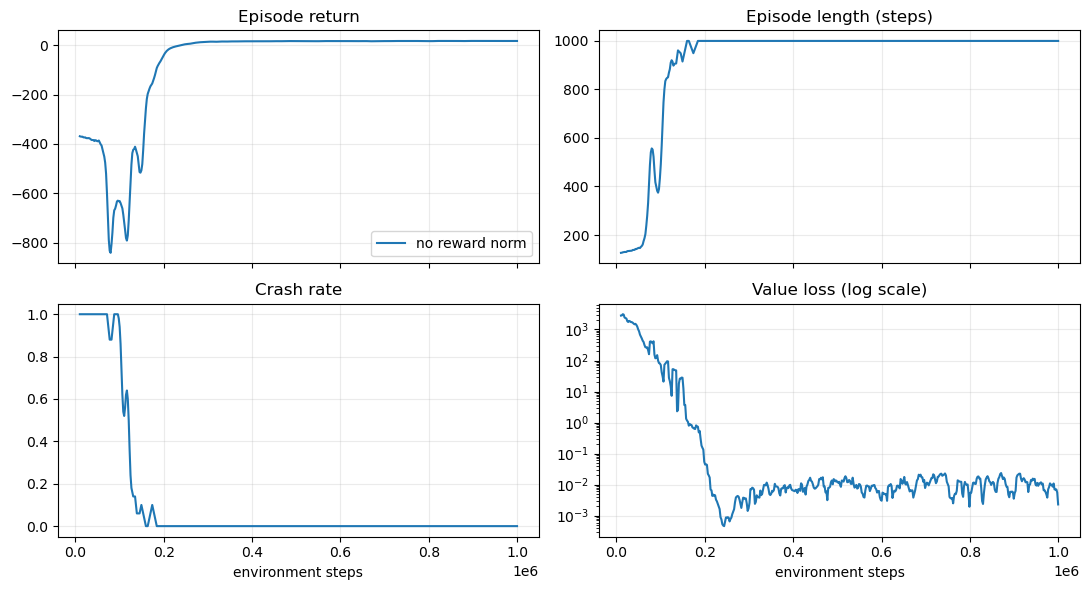

In [15]:
def plot_training_history(runs, window=5, save_path=None):
    """runs: {label: history}. One line per run on 4 diagnostic panels (moving average)."""
    panels = [("mean_return", "Episode return"), ("mean_length", "Episode length (steps)"),
              ("crash_rate", "Crash rate"), ("v_loss", "Value loss (log scale)")]
    fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
    for ax, (key, title) in zip(axes.flat, panels):
        for label, hist in runs.items():
            x = np.array([h["timesteps"] for h in hist])
            y = np.array([h[key] for h in hist], dtype=float)
            if len(y) >= window:
                y, x = np.convolve(y, np.ones(window) / window, mode="valid"), x[window - 1:]
            ax.plot(x, y, label=label)
        ax.set_title(title)
        ax.grid(alpha=0.25)
    axes[1, 1].set_yscale("log")
    for ax in axes[1]:
        ax.set_xlabel("environment steps")
    axes[0, 0].legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_training_history({"no reward norm": base_run["history"]},
                      save_path=PLOT_DIR / f"diagnostics_{RUN_TAG}.png")

**5.3 Stability across seeds.** The same configuration trained with seeds 0, 1 and 2. Seed 0 is the run from 5.1, so it is loaded, not retrained; seeds 1 and 2 are trained here (or loaded if they already finished), each with its own tag. The overlaid curves show whether PPO learns the same way regardless of the random seed.

In [16]:
SEEDS = [0, 1, 2]
seed_runs = {seed: train_or_load(level=EXPERIMENT["level"], seed=seed) for seed in SEEDS}

L0_seed0: already trained, loaded from notebooks/runs/ppo_25609227/long/logs/L0_seed0.json (20.0 min)


update 1/488 | steps 2048 | mean return -364.74 | ep_len 122.7 | crash 100% | pg_loss -0.017 | v_loss 4105.851 | entropy 5.697 | approx_kl 0.00517 | clipfrac 0.055
New best checkpoint saved (L0_seed1_best).


update 2/488 | steps 4096 | mean return -364.83 | ep_len 123.6 | crash 100% | pg_loss -0.022 | v_loss 4076.211 | entropy 5.686 | approx_kl 0.00507 | clipfrac 0.049


update 3/488 | steps 6144 | mean return -366.96 | ep_len 130.5 | crash 100% | pg_loss 0.021 | v_loss 3004.640 | entropy 5.706 | approx_kl 0.00737 | clipfrac 0.078


update 4/488 | steps 8192 | mean return -361.08 | ep_len 122.8 | crash 100% | pg_loss -0.012 | v_loss 2862.723 | entropy 5.687 | approx_kl 0.00557 | clipfrac 0.065
New best checkpoint saved (L0_seed1_best).


update 5/488 | steps 10240 | mean return -363.62 | ep_len 121.3 | crash 100% | pg_loss -0.015 | v_loss 2416.340 | entropy 5.735 | approx_kl 0.00512 | clipfrac 0.055


... (967 outputs left out)

update 485/488 | steps 993280 | mean return 17.00 | ep_len 1000.0 | crash 0% | pg_loss 0.003 | v_loss 0.000 | entropy -0.081 | approx_kl 0.00010 | clipfrac 0.000


update 486/488 | steps 995328 | mean return 17.01 | ep_len 1000.0 | crash 0% | pg_loss -0.002 | v_loss 0.020 | entropy -0.081 | approx_kl 0.00006 | clipfrac 0.000


update 487/488 | steps 997376 | mean return 17.03 | ep_len 1000.0 | crash 0% | pg_loss -0.006 | v_loss 0.005 | entropy -0.081 | approx_kl 0.00023 | clipfrac 0.000


update 488/488 | steps 999424 | mean return 17.06 | ep_len 1000.0 | crash 0% | pg_loss -0.000 | v_loss 0.012 | entropy -0.081 | approx_kl 0.00002 | clipfrac 0.000
L0_seed2: trained in 20.1 min, log saved to notebooks/runs/ppo_25609227/long/logs/L0_seed2.json


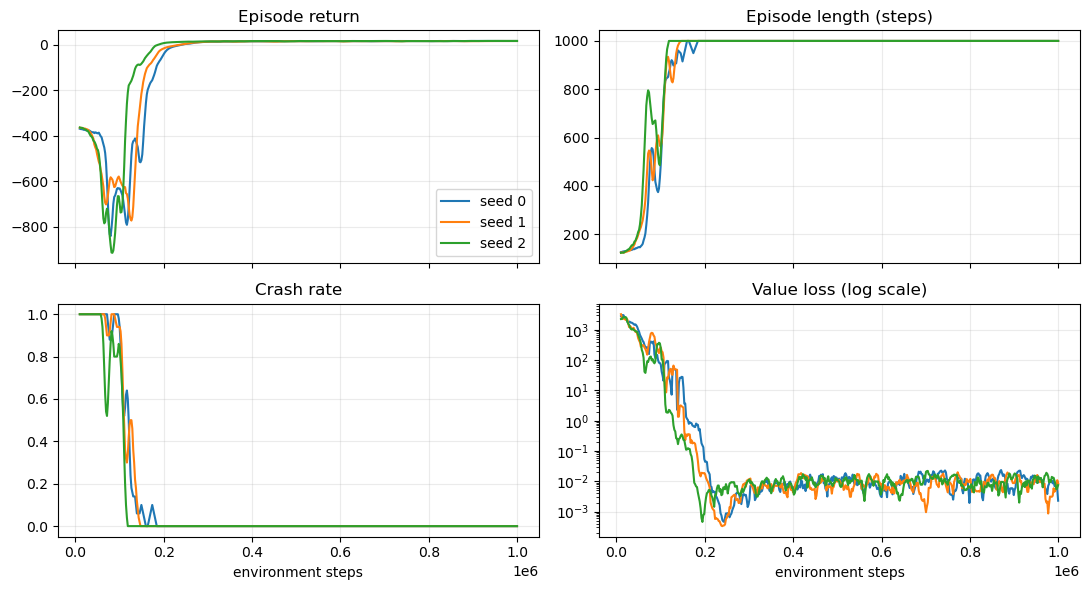

In [17]:
plot_training_history({f"seed {s}": r["history"] for s, r in seed_runs.items()},
                      save_path=PLOT_DIR / f"seeds_L{EXPERIMENT['level']}.png")

**5.4 Final experiment: L0 to L4, 3 seeds each.** 15 runs of `TRAIN_BUDGET` steps, with the same protocol as REINFORCE (`results/reinforce/runs/`), so the two are compared one to one: same levels, seeds, budget, reward (`crash_penalty=300`) and a checkpoint every `CKPT_EVERY` steps. The hyperparameters are the same at every level (set at L0, never tuned per level). The L0 runs are the ones from 5.1 and 5.3, so they are loaded.

About 8 to 10 minutes per run on a laptop CPU, so 2 to 3 hours in total. Keep the machine awake (on a Mac: `caffeinate -i` in a terminal) or run it on SageMaker. If the kernel dies, run this cell again: finished runs are loaded, not retrained.

In [18]:
LEVELS = [0, 1, 2, 3, 4]
runs = {}
for level in LEVELS:
    for seed in SEEDS:
        runs[run_tag(level, seed)] = train_or_load(level=level, seed=seed)

L0_seed0: already trained, loaded from notebooks/runs/ppo_25609227/long/logs/L0_seed0.json (20.0 min)
L0_seed1: already trained, loaded from notebooks/runs/ppo_25609227/long/logs/L0_seed1.json (20.1 min)
L0_seed2: already trained, loaded from notebooks/runs/ppo_25609227/long/logs/L0_seed2.json (20.1 min)


update 1/488 | steps 2048 | mean return -366.34 | ep_len 123.0 | crash 100% | pg_loss -0.014 | v_loss 2229.865 | entropy 5.714 | approx_kl 0.00828 | clipfrac 0.063
New best checkpoint saved (L1_seed0_best).


update 2/488 | steps 4096 | mean return -365.24 | ep_len 123.6 | crash 100% | pg_loss -0.000 | v_loss 2183.087 | entropy 5.736 | approx_kl 0.00882 | clipfrac 0.065
New best checkpoint saved (L1_seed0_best).


update 3/488 | steps 6144 | mean return -375.29 | ep_len 124.1 | crash 100% | pg_loss -0.005 | v_loss 1535.499 | entropy 5.743 | approx_kl 0.00535 | clipfrac 0.075


update 4/488 | steps 8192 | mean return -368.70 | ep_len 131.2 | crash 100% | pg_loss 0.013 | v_loss 1480.632 | entropy 5.752 | approx_kl 0.00625 | clipfrac 0.049


update 5/488 | steps 10240 | mean return -371.92 | ep_len 126.0 | crash 100% | pg_loss -0.005 | v_loss 1790.847 | entropy 5.744 | approx_kl 0.00495 | clipfrac 0.041


... (5,847 outputs left out)

update 485/488 | steps 993280 | mean return 94.90 | ep_len 402.0 | crash 0% | pg_loss -0.003 | v_loss 0.015 | entropy 1.320 | approx_kl 0.00353 | clipfrac 0.003


update 486/488 | steps 995328 | mean return 94.67 | ep_len 401.5 | crash 0% | pg_loss -0.001 | v_loss 0.011 | entropy 1.320 | approx_kl 0.00054 | clipfrac 0.000


update 487/488 | steps 997376 | mean return 94.75 | ep_len 401.6 | crash 0% | pg_loss 0.001 | v_loss 0.016 | entropy 1.320 | approx_kl 0.00012 | clipfrac 0.000


update 488/488 | steps 999424 | mean return 95.09 | ep_len 402.4 | crash 0% | pg_loss -0.002 | v_loss 0.006 | entropy 1.320 | approx_kl 0.00013 | clipfrac 0.000
L4_seed2: trained in 20.2 min, log saved to notebooks/runs/ppo_25609227/long/logs/L4_seed2.json


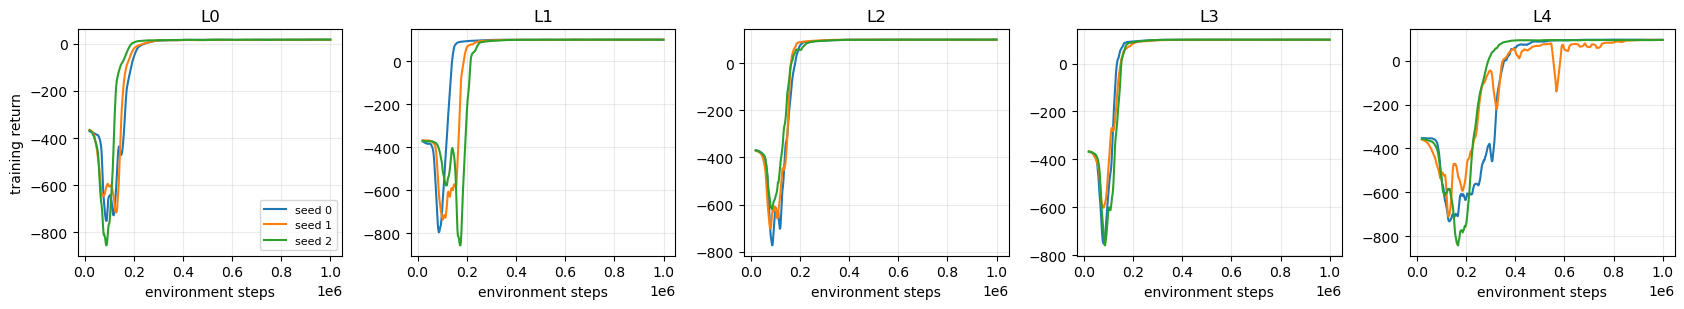

In [19]:
def plot_curves_by_level(runs, window=10, save_path=None):
    """One panel per level, one line per seed: training return (moving average over updates)."""
    fig, axes = plt.subplots(1, len(LEVELS), figsize=(17, 3.2))
    for ax, level in zip(axes, LEVELS):
        for seed in SEEDS:
            curve = runs[run_tag(level, seed)]["curve"]
            x = np.array([p["timesteps"] for p in curve])
            y = np.array([p["mean_return"] for p in curve], dtype=float)
            if len(y) >= window:
                y, x = np.convolve(y, np.ones(window) / window, mode="valid"), x[window - 1:]
            ax.plot(x, y, label=f"seed {seed}")
        ax.set_title(f"L{level}")
        ax.set_xlabel("environment steps")
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("training return")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_curves_by_level(runs, save_path=PLOT_DIR / "training_curves_L0-L4.png")

<a id="evaluation"></a>

## 6. Evaluation

Every policy is evaluated on the same held-out seeds (1000 to 1019), which are never used in training, so the three algorithms face exactly the same 20 episodes. PPO is evaluated **deterministically** (the mean of the Gaussian, no exploration noise), as committed in Part B.

**6.1 Baselines: what does a policy that learns nothing score?** A learned policy is only useful if it beats these. Each one is evaluated at every level, with the same seeds and the same random generator as REINFORCE (`scripts/assemble_reinforce_results.py`), so the numbers match Juan's.
- `zero_action`: always sends 0, so the inner controller simply holds position. At L0 this is the bar to beat.
- `altitude_hold`: a hand-coded proportional controller on altitude.
- `random`: small random actions (scale 0.3 of the action range), not uniform over [-1, 1].

In [20]:
from agroflight.evaluation.evaluate_policy import evaluate
from agroflight.baselines import altitude_hold_action, random_action

def make_eval_env(level):
    return gym.make(ENV_ID, level=level, reward_config=EXPERIMENT["reward_config"])

baselines = RESULTS["evaluation"]["baselines"]
rng = np.random.default_rng(0)   # one generator for all levels, in the same order as REINFORCE
for level in LEVELS:
    env_l = make_eval_env(level)
    policies = {
        "zero_action": lambda obs: np.zeros(4, dtype=np.float32),
        "altitude_hold": altitude_hold_action,
        "random": lambda obs: random_action(env_l.action_space, rng),
    }
    for name, policy in policies.items():
        baselines[f"{name}@L{level}"] = evaluate(policy, seeds=EXPERIMENT["eval_seeds"], env=env_l)
        st = baselines[f"{name}@L{level}"]
        print(f"{name + '@L' + str(level):<17} reward {st['mean_reward']:8.1f}  crash {st['crash_rate']:.0%}  "
              f"finish {st['finish_rate']:.0%}")
    env_l.close()
baselines["altitude_hold"], baselines["random"] = baselines["altitude_hold@L0"], baselines["random@L0"]

zero_action@L0    reward     14.9  crash 0%  finish 0%


altitude_hold@L0  reward     19.8  crash 0%  finish 0%


random@L0         reward      6.5  crash 0%  finish 0%


zero_action@L1    reward     -1.0  crash 0%  finish 0%


altitude_hold@L1  reward      3.9  crash 0%  finish 0%


random@L1         reward     -9.9  crash 0%  finish 0%


... (5 outputs left out)

random@L3         reward   -176.1  crash 0%  finish 0%


zero_action@L4    reward   -163.8  crash 0%  finish 0%


altitude_hold@L4  reward   -153.4  crash 0%  finish 0%


random@L4         reward   -177.9  crash 0%  finish 0%


**6.2 Load the trained policy.** Turns the saved checkpoint into a function `obs -> action`. The network is rebuilt, the weights are loaded, and the action is the output of `actor_mean` directly, without sampling from the Gaussian.

In [21]:
def load_ppo_policy(tag):
    """Rebuild the network, load its weights and return a DETERMINISTIC policy obs -> action."""
    agent = Agent(obs_dim=14, act_dim=4)
    load_checkpoint(agent, tag=tag)
    agent.eval()

    def policy(obs):
        obs = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)   # (14,) -> (1, 14)
        with torch.no_grad():
            action = agent.actor_mean(obs)                             # Gaussian mean: no sampling
        return action.squeeze(0).numpy()                               # (1, 4) -> (4,)
    return policy


**6.3 Evaluate every checkpoint of every run.** Each checkpoint is evaluated at the level it was trained on, on the 20 held-out seeds, deterministically. The `step_...` checkpoints give an evaluation learning curve; `final` is the reported result. The evaluation is stored in the run log (`checkpoint_eval`), so it runs once per run: about 1 to 2 minutes each.

In [22]:
def evaluate_run(run):
    """Evaluate every checkpoint of one run at its own level; computed once, then read from the run log."""
    if "checkpoint_eval" in run:
        return run["checkpoint_eval"]
    env_l = make_eval_env(run["level"])
    try:
        # Keys "step_0100k.pt", "final.pt", "best.pt": the same as REINFORCE's checkpoint_eval
        run["checkpoint_eval"] = {
            f"{name}.pt": dict(timesteps=step, **evaluate(load_ppo_policy(f"{run['tag']}_{name}"),
                                                          seeds=EXPERIMENT["eval_seeds"], env=env_l))
            for name, step in run["checkpoints"].items()}
    finally:
        env_l.close()
    with open(LOG_DIR / f"{run['tag']}.json", "w") as f:
        json.dump(run, f)
    return run["checkpoint_eval"]

for tag, run in runs.items():
    st = evaluate_run(run)["final.pt"]
    print(f"{tag:<9} final: reward {st['mean_reward']:8.1f}  crash {st['crash_rate']:.0%}  "
          f"finish {st['finish_rate']:.0%}  |alt err| {st['mean_abs_alt_error']:.3f} m")

L0_seed0  final: reward     19.7  crash 0%  finish 0%  |alt err| 0.004 m


L0_seed1  final: reward     19.7  crash 0%  finish 0%  |alt err| 0.003 m


L0_seed2  final: reward     19.8  crash 0%  finish 0%  |alt err| 0.008 m


L1_seed0  final: reward    100.1  crash 0%  finish 100%  |alt err| 0.007 m


L1_seed1  final: reward    100.3  crash 0%  finish 100%  |alt err| 0.008 m


L1_seed2  final: reward    100.1  crash 0%  finish 100%  |alt err| 0.014 m


... (5 outputs left out)

L3_seed2  final: reward     99.9  crash 0%  finish 100%  |alt err| 0.017 m


L4_seed0  final: reward     98.0  crash 0%  finish 100%  |alt err| 0.009 m


L4_seed1  final: reward     95.6  crash 0%  finish 100%  |alt err| 0.036 m


L4_seed2  final: reward     95.3  crash 0%  finish 100%  |alt err| 0.012 m


**6.4 Success criterion and samples needed.** A level is **cleared** by a policy when it crashes in at most 5% of the 20 evaluation episodes and, at L0, keeps the altitude error below 0.05 m, or, from L1 on, completes the row in at least 90% of them. This is the criterion REINFORCE uses (Section 7b of `reinforce_25418551.ipynb`). **Samples needed** = environment steps of the first `step_...` or `final` checkpoint that clears the level, so it is measured every `CKPT_EVERY` steps. Part B reports the highest level each algorithm clears and the samples it needed.

In [23]:
def cleared(st, level):
    """Same criterion as REINFORCE."""
    if st["crash_rate"] > 0.05:
        return False
    return st["mean_abs_alt_error"] < 0.05 if level == 0 else st["finish_rate"] >= 0.90

def samples_to_clear(run):
    """Steps of the first periodic (or final) checkpoint that clears the run's level; None if none does."""
    evals = sorted((v for k, v in run["checkpoint_eval"].items() if k != "best.pt"), key=lambda v: v["timesteps"])
    return next((v["timesteps"] for v in evals if cleared(v, run["level"])), None)

for tag, run in runs.items():
    n = samples_to_clear(run)
    print(f"{tag:<9} cleared at the end: {cleared(run['checkpoint_eval']['final.pt'], run['level'])!s:<5}  "
          f"samples needed: {f'{n:,}' if n else 'never cleared'}")

L0_seed0  cleared at the end: True   samples needed: 301,056
L0_seed1  cleared at the end: True   samples needed: 301,056
L0_seed2  cleared at the end: True   samples needed: 200,704
L1_seed0  cleared at the end: True   samples needed: 200,704
L1_seed1  cleared at the end: True   samples needed: 200,704
L1_seed2  cleared at the end: True   samples needed: 301,056
L2_seed0  cleared at the end: True   samples needed: 200,704
L2_seed1  cleared at the end: True   samples needed: 200,704
L2_seed2  cleared at the end: True   samples needed: 200,704
L3_seed0  cleared at the end: True   samples needed: 200,704
L3_seed1  cleared at the end: True   samples needed: 200,704
L3_seed2  cleared at the end: True   samples needed: 200,704
L4_seed0  cleared at the end: True   samples needed: 501,760
L4_seed1  cleared at the end: True   samples needed: 501,760
L4_seed2  cleared at the end: True   samples needed: 301,056


<a id="results"></a>

## 7. Results

In [24]:
import pandas as pd
STAT_KEYS = ["mean_reward", "std_reward", "crash_rate", "finish_rate", "mean_steps", "mean_abs_alt_error"]

def mean_stats(stats):
    """Mean over the training seeds (same as scripts/assemble_reinforce_results.py)."""
    out = {k: float(np.mean([s[k] for s in stats])) for k in STAT_KEYS}
    out["n_episodes"] = int(sum(s["n_episodes"] for s in stats))
    out["n_seeds"] = len(stats)
    return out

# Same keys as results/reinforce_25418551.json, so the comparison reads both files the same way:
#   per_seed[Ln_seedS] = final checkpoint, best_ckpt[Ln_seedS] = best checkpoint, levels[Ln] = mean of the seeds
ev = RESULTS["evaluation"]
ev["per_seed"] = {tag: {k: r["checkpoint_eval"]["final.pt"][k] for k in STAT_KEYS + ["n_episodes"]} for tag, r in runs.items()}
ev["best_ckpt"] = {tag: {k: r["checkpoint_eval"]["best.pt"][k] for k in STAT_KEYS + ["n_episodes"]} for tag, r in runs.items()}
ev["levels"] = {f"L{lv}": mean_stats([ev["per_seed"][run_tag(lv, s)] for s in SEEDS]) for lv in LEVELS}
RESULTS["training"]["runs"] = {
    tag: dict(level=r["level"], train_seed=r["seed"], total_timesteps=r["total_timesteps"], wall_clock_s=r["wall_s"],
              samples_to_clear=samples_to_clear(r), curve=r["curve"], checkpoint_eval=r["checkpoint_eval"])
    for tag, r in runs.items()}

**7.1 Results per run and per level.** The first table has one row per run (final checkpoint). The second summarises each level over the 3 seeds, next to the baselines.

In [25]:
df_runs = pd.DataFrame([
    {"run": tag, "level": r["level"], "cleared": cleared(ev["per_seed"][tag], r["level"]),
     "samples to clear": samples_to_clear(r), **{k: ev["per_seed"][tag][k] for k in STAT_KEYS}}
    for tag, r in runs.items()]).set_index("run")
display(df_runs.round(3))

df_levels = pd.DataFrame([
    {"level": f"L{lv}", "seeds cleared": f"{int(d.cleared.sum())} of {len(d)}",
     "median samples to clear": d["samples to clear"].median(),
     "PPO reward (mean of seeds)": d.mean_reward.mean(), "std across seeds": d.mean_reward.std(),
     "crash rate": d.crash_rate.mean(), "finish rate": d.finish_rate.mean(),
     "altitude-hold reward": ev["baselines"][f"altitude_hold@L{lv}"]["mean_reward"],
     "zero-action reward": ev["baselines"][f"zero_action@L{lv}"]["mean_reward"]}
    for lv in LEVELS for d in [df_runs[df_runs.level == lv]]]).set_index("level")
display(df_levels.round(3))

,level,cleared,samples to clear,mean_reward,std_reward,crash_rate,finish_rate,mean_steps,mean_abs_alt_error
run,,,,,,,,,
L0_seed0,0,True,301056,19.653,0.106,0.0,0.0,1000.00,0.004
L0_seed1,0,True,301056,19.704,0.107,0.0,0.0,1000.00,0.003
L0_seed2,0,True,200704,19.783,0.110,0.0,0.0,1000.00,0.008
L1_seed0,1,True,200704,100.063,0.718,0.0,1.0,434.55,0.007
L1_seed1,1,True,200704,100.336,0.648,0.0,1.0,435.10,0.008
L1_seed2,1,True,301056,100.066,0.751,0.0,1.0,434.60,0.014
L2_seed0,2,True,200704,99.705,0.803,0.0,1.0,435.15,0.010
L2_seed1,2,True,200704,99.736,0.774,0.0,1.0,434.40,0.008
L2_seed2,2,True,200704,99.798,0.751,0.0,1.0,434.75,0.009


,seeds cleared,median samples to clear,PPO reward (mean of seeds),std across seeds,crash rate,finish rate,altitude-hold reward,zero-action reward
level,,,,,,,,
L0,3 of 3,301056.0,19.713,0.066,0.0,0.0,19.781,14.862
L1,3 of 3,200704.0,100.155,0.157,0.0,1.0,3.914,-1.005
L2,3 of 3,200704.0,99.746,0.047,0.0,1.0,-712.672,-716.876
L3,3 of 3,200704.0,99.859,0.043,0.0,1.0,-153.365,-163.823
L4,3 of 3,501760.0,96.281,1.458,0.0,1.0,-153.365,-163.823


**7.2 Evaluation learning curves.** Each point is one checkpoint evaluated on the held-out seeds. Top: mean reward, with altitude-hold as a dotted line. Bottom: crash rate (solid) and row completion rate (dashed). The first point that meets the criterion of 6.4 is the "samples needed".

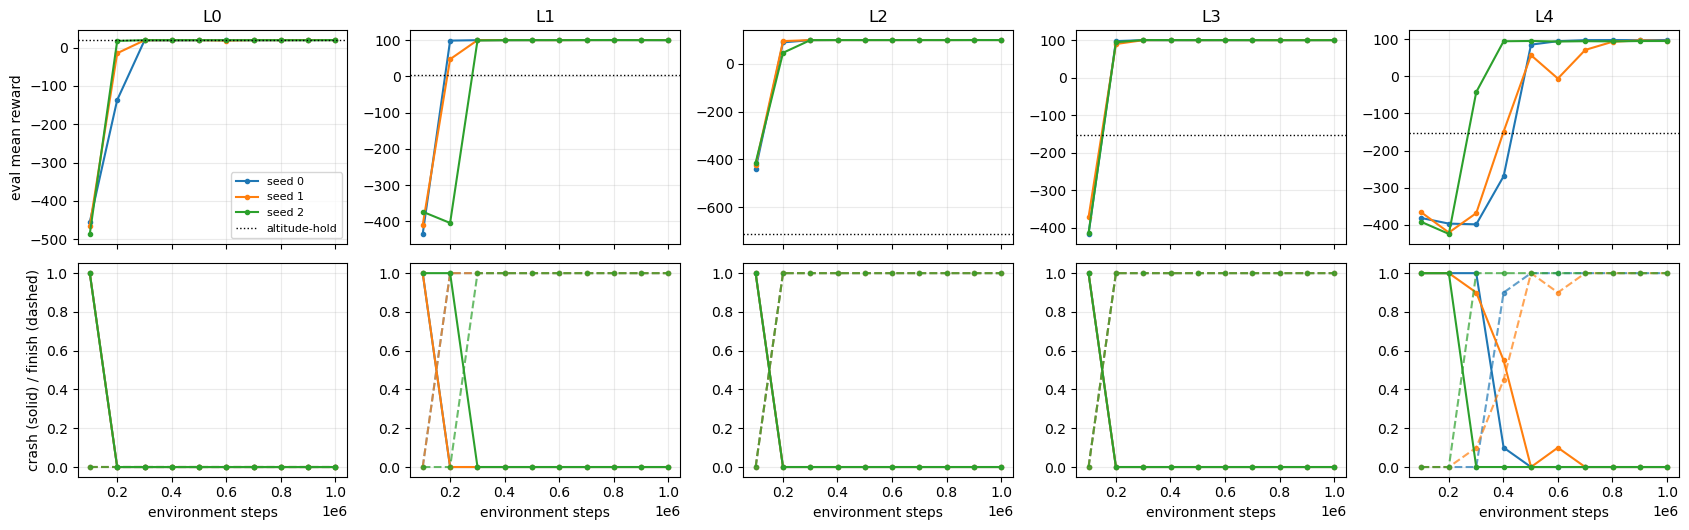

In [26]:
fig, axes = plt.subplots(2, len(LEVELS), figsize=(17, 5.4), sharex=True)
for col, lv in enumerate(LEVELS):
    for s in SEEDS:
        ce = runs[run_tag(lv, s)]["checkpoint_eval"]
        pts = sorted((v for k, v in ce.items() if k != "best.pt"), key=lambda v: v["timesteps"])
        x = [p["timesteps"] for p in pts]
        axes[0, col].plot(x, [p["mean_reward"] for p in pts], "o-", ms=3, color=f"C{s}", label=f"seed {s}")
        axes[1, col].plot(x, [p["crash_rate"] for p in pts], "o-", ms=3, color=f"C{s}")
        axes[1, col].plot(x, [p["finish_rate"] for p in pts], "o--", ms=3, color=f"C{s}", alpha=0.7)
    axes[0, col].axhline(ev["baselines"][f"altitude_hold@L{lv}"]["mean_reward"], color="k", ls=":", lw=1,
                         label="altitude-hold" if col == 0 else None)
    axes[0, col].set_title(f"L{lv}")
    axes[1, col].set_ylim(-0.05, 1.05)
    axes[1, col].set_xlabel("environment steps")
    for ax in axes[:, col]:
        ax.grid(alpha=0.25)
axes[0, 0].set_ylabel("eval mean reward")
axes[1, 0].set_ylabel("crash (solid) / finish (dashed)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(PLOT_DIR / "checkpoint_eval_L0-L4.png", dpi=150, bbox_inches="tight")
plt.show()

**7.3 PPO against the baselines, and save.** Bars: PPO (mean of the 3 seeds, dots = each seed) and the three baselines, per level. Then the tables go to the run folder and, in `long` mode only, the results to `results/ppo_25609227.json`.

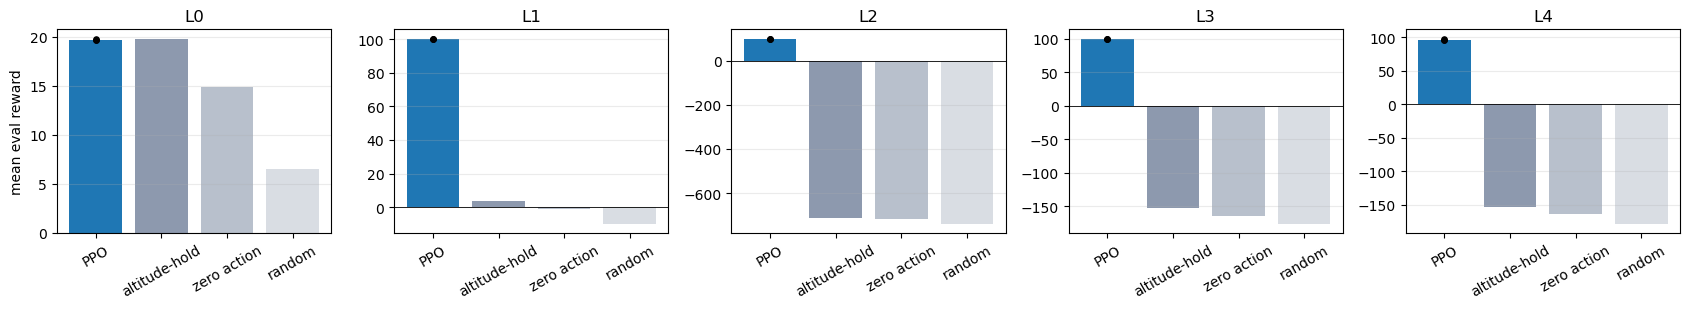

tables saved to notebooks/runs/ppo_25609227/long
results saved to /home/sagemaker-user/agroflight-rl/results/ppo_25609227.json


In [27]:
fig, axes = plt.subplots(1, len(LEVELS), figsize=(17, 3.2))
for ax, lv in zip(axes, LEVELS):
    seed_rewards = [ev["per_seed"][run_tag(lv, s)]["mean_reward"] for s in SEEDS]
    names = ["PPO", "altitude-hold", "zero action", "random"]
    means = [np.mean(seed_rewards)] + [ev["baselines"][f"{b}@L{lv}"]["mean_reward"]
                                       for b in ("altitude_hold", "zero_action", "random")]
    ax.bar(names, means, color=["C0", "#8d99ae", "#b8c0cc", "#d9dde3"])
    ax.scatter(["PPO"] * len(seed_rewards), seed_rewards, color="k", s=14, zorder=3)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"L{lv}")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("mean eval reward")
plt.tight_layout()
plt.savefig(PLOT_DIR / "ppo_vs_baselines.png", dpi=150, bbox_inches="tight")
plt.show()

df_runs.to_csv(RUN_DIR / "results_runs.csv")
df_levels.to_csv(RUN_DIR / "results_levels.csv")
print("tables saved to", RUN_DIR.relative_to(REPO))
# A smoke test must not overwrite the shared results file that the comparison notebook reads
if RUN_MODE == "long":
    path = save_results(RESULTS)
    print("results saved to", path)
else:
    print("smoke run: results/ left untouched")
if BACKUP_TO_DRIVE:
    backup_to_drive([RESULTS_DIR, str(RUN_DIR.parent)])

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> State the headline result in one sentence: the highest level cleared and the samples it needed. Compare against both baselines and against your success criterion from Section 1. Report what did not work as well as what did.</div>

<a id="discussion"></a>

## 8. Discussion

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> <ul><li>Was training stable across seeds? Show the spread, not just the best run.</li><li>Did the reward behave as intended, or did you see reward hacking (for example hovering in place)? Check the viewer, not only the number.</li><li>Where did the algorithm fail, and is that the algorithm, the reward, or the environment?</li><li>Limits: MuJoCo has no rotor ground effect or canopy turbulence; wind is observable; single environment.</li><li>What would you try next with more time?</li></ul></div>

<a id="contribution"></a>

## 9. Contribution and reproducibility

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Contribution statement (marks are split by individual contribution). Fill in the table.</div>

| | |
|---|---|
| **My contribution** | *what Nelkit built, ran and wrote* |
| **Shared work with teammates** | *environment rework, evaluation harness, viewer, report sections* |
| **AI assistance used** | *which tool, for what, and what you verified yourself* |

In [28]:
import platform
print("python    :", platform.python_version())
print("torch     :", torch.__version__)
print("numpy     :", np.__version__)
print("gymnasium :", gym.__version__)
print("mujoco    :", mujoco.__version__)
print("git commit:", git_commit())
print("train seed:", EXPERIMENT["train_seed"], "| eval seeds:", EXPERIMENT["eval_seeds"][0], "to", EXPERIMENT["eval_seeds"][-1])
print("notebook wall-clock so far: %.0f s" % (time.time() - NOTEBOOK_T0))

python    : 3.12.14
torch     : 2.8.0
numpy     : 1.26.4
gymnasium : 1.4.0
mujoco    : 3.16.0
git commit: 50ffd25
train seed: 0 | eval seeds: 1000 to 1019
notebook wall-clock so far: 18850 s


### References

1. Schulman, J., Wolski, F., Dhariwal, P., Radford, A., Klimov, O. (2017). Proximal Policy Optimization Algorithms. arXiv:1707.06347.
2. Schulman, J., Moritz, P., Levine, S., Jordan, M., Abbeel, P. (2016). High-Dimensional Continuous Control Using Generalized Advantage Estimation. ICLR. arXiv:1506.02438.
3. Huang, S. et al. (2022). CleanRL: High-quality Single-file Implementations of Deep Reinforcement Learning Algorithms. JMLR 23(274).
4. Todorov, E., Erez, T., Tassa, Y. (2012). MuJoCo: A physics engine for model-based control. IROS.
5. Google DeepMind. MuJoCo Menagerie: Skydio X2 model (Apache-2.0). github.com/google-deepmind/mujoco_menagerie.
6. Towers, M. et al. (2024). Gymnasium: A Standard Interface for Reinforcement Learning Environments. arXiv:2407.17032.